These are the GWR related code blocks from my complete (for thesis) notebook. they won't run outside of the submitted project notebook but I wanted that one to be cleaner than what I have going on in the complete one.
- Basically, residualizing imperviousness was a suggestion from the web to better things, creating centroids for representing tracts
- then had to get rid of rows that had missing values in any predictor or the target for GWR to not give an error, which lost a lot of census tracts, so I may need to find another way of accounting for this in the GWR.
- Next, colinearity check, and only white population was dropped... Seems off so will change this
- Then will run a PCA on colinear variables to have a composite predictor

- Here, after preprocessing, GWR is run, and Local R2's and coefficients of each variable is mapped (visuals in submission folder Appendix 2)
- R2's seem to have outliers on the Rockaways and around a golf course in south Brooklyn, which I'll have to think about while building the model more.

In [ ]:
## First, I want to make sure the imperviousness raster is residualized, as it is highly impacted by histroic demographic patterns.
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.decomposition import PCA

demographics = ["pct_poverty", "pct_bachelors_up", "pct_white", "pct_black", "pct_hispanic", "pct_englimit"]
gwr_df_clean = gwr_df.copy()
for col in demographics:
    gwr_df_clean[col] = pd.to_numeric(gwr_df_clean[col], errors='coerce')

gwr_df_clean = gwr_df_clean.dropna(subset=demographics + ["impervious_frac", "pct_poor"])
print(f"Rows after cleaning: {len(gwr_df_clean)}")
X_demo = gwr_df_clean[demographics].values
y_imperv = gwr_df_clean["impervious_frac"].values.reshape(-1, 1)

lr = LinearRegression()
lr.fit(X_demo, y_imperv)
imperv_resid = y_imperv - lr.predict(X_demo)

gwr_df_clean["imperv_resid"] = imperv_resid.flatten()


Rows after cleaning: 1985


In [ ]:
predictors = demographics + ["imperv_resid"]
target = "pct_poor"
for col in predictors + [target]:
    gwr_df_clean[col] = pd.to_numeric(gwr_df_clean[col], errors="coerce")

In [ ]:
X_clean = gwr_df_clean[predictors].copy()
reduced_predictors = X_clean.columns.tolist()

## Dropping highly colinear demographic predictors to have a cleaner model.
while len(reduced_predictors) > 1:
    reduced_predictors = [col for col in reduced_predictors if X_clean[col].std() > 0]

    if len(reduced_predictors) < 2:
        break

    vif_values = [variance_inflation_factor(X_clean[reduced_predictors].values, i) for i in range(len(reduced_predictors))]
    max_vif = max(vif_values)

    if max_vif <= 5:
        break

    drop_var = reduced_predictors[vif_values.index(max_vif)]  #checks for if the code worked (chat helped me)
    print(f"Dropping {drop_var} with VIF={max_vif:.2f}")
    reduced_predictors.remove(drop_var)

print(f"Predictors kept after VIF check: {reduced_predictors}")


Dropping pct_white with VIF=6.00
Predictors kept after VIF check: ['pct_poverty', 'pct_bachelors_up', 'pct_black', 'pct_hispanic', 'pct_englimit', 'imperv_resid']


In [ ]:
# Checking CRS
gwr_df_clean = gwr_df_clean.to_crs(2263)
gwr_df_clean["x"] = gwr_df_clean.geometry.centroid.x
gwr_df_clean["y"] = gwr_df_clean.geometry.centroid.y
coords = list(zip(gwr_df_clean["x"], gwr_df_clean["y"]))

I want to quickly run a kernel density on poor tree health.

Now onto GWR Trials

In [ ]:
scaler = StandardScaler()
X_std = scaler.fit_transform(final_predictors_df.values)
y = gwr_df_clean[target].values.reshape(-1,1)

In [ ]:
from mgwr.sel_bw import Sel_BW
from mgwr.gwr import GWR

bw = Sel_BW(coords, y, X_std).search()
print(f"Selected GWR bandwidth: {bw}")

gwr_model = GWR(coords, y, X_std, bw=bw, fixed=False).fit()
print(gwr_model.summary())

Selected GWR bandwidth: 167.0
Model type                                                         Gaussian
Number of observations:                                                1985
Number of covariates:                                                     8

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                          24652.238
Log-likelihood:                                                   -5316.947
AIC:                                                              10649.895
AICc:                                                             10651.986
BIC:                                                               9640.137
R2:                                                                   0.052
Adj. R2:                                                              0.048

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------

In [ ]:
gwr_df_clean["local_R2"] = gwr_model.localR2

for i, col in enumerate(final_predictors_df.columns):
    gwr_df_clean[f"coef_{col}"] = gwr_model.params[:, i]

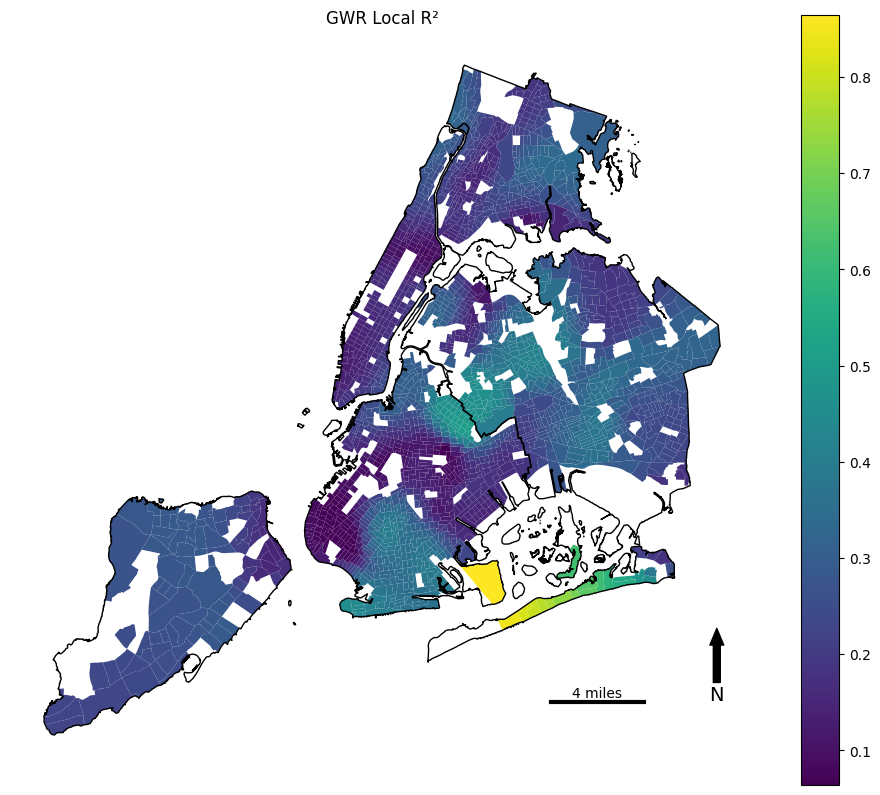

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 10))

gwr_df_clean.plot(
    column="local_R2",
    cmap="viridis",
    legend=True,
    ax=ax,
    edgecolor="none"
)

boroughs_gdf.boundary.plot(ax=ax, color="black", linewidth=1)
add_north_arrow(ax)
add_scale_bar(ax, gwr_df_clean)

ax.set_title("GWR Local R²")
ax.axis("off")
plt.show()


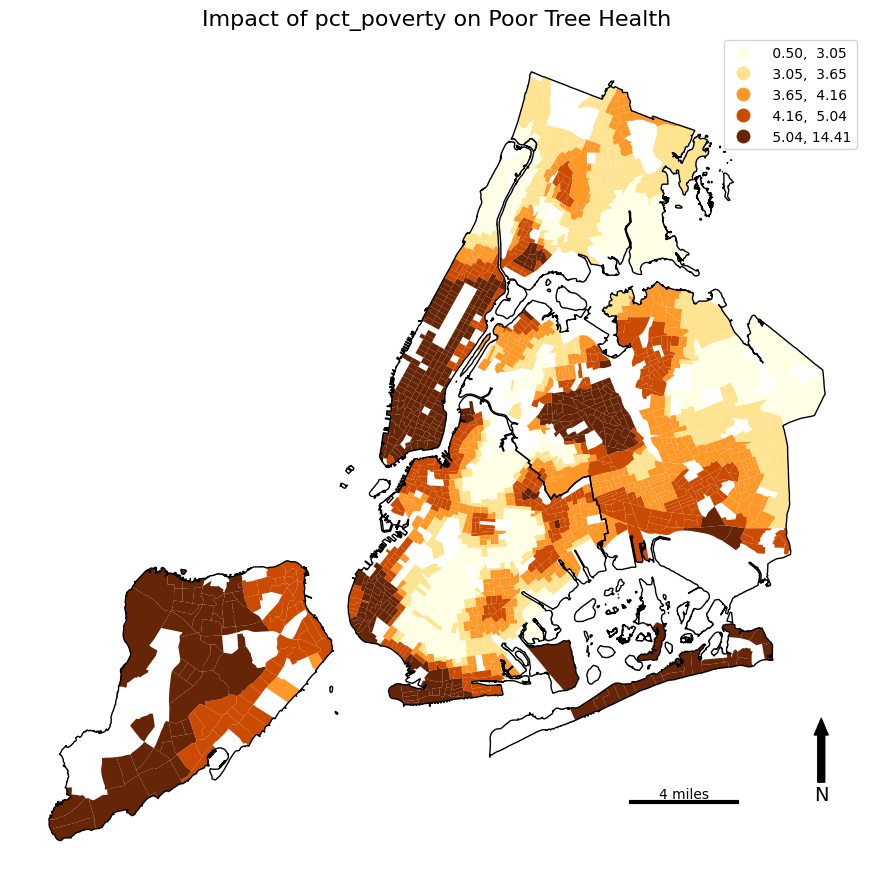

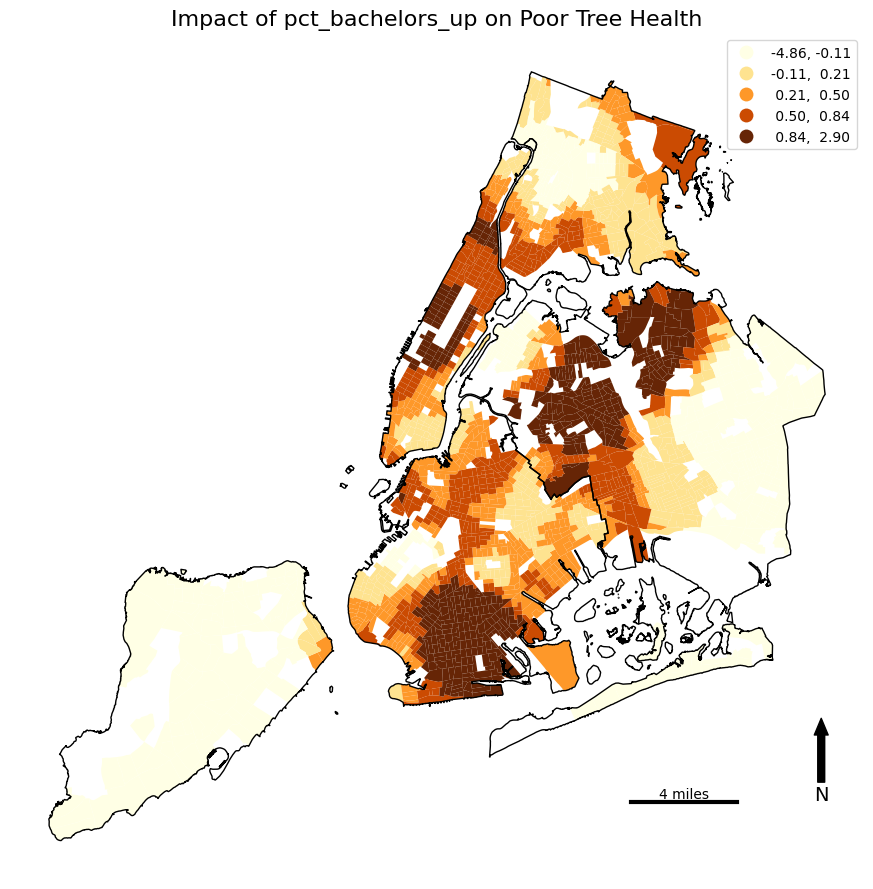

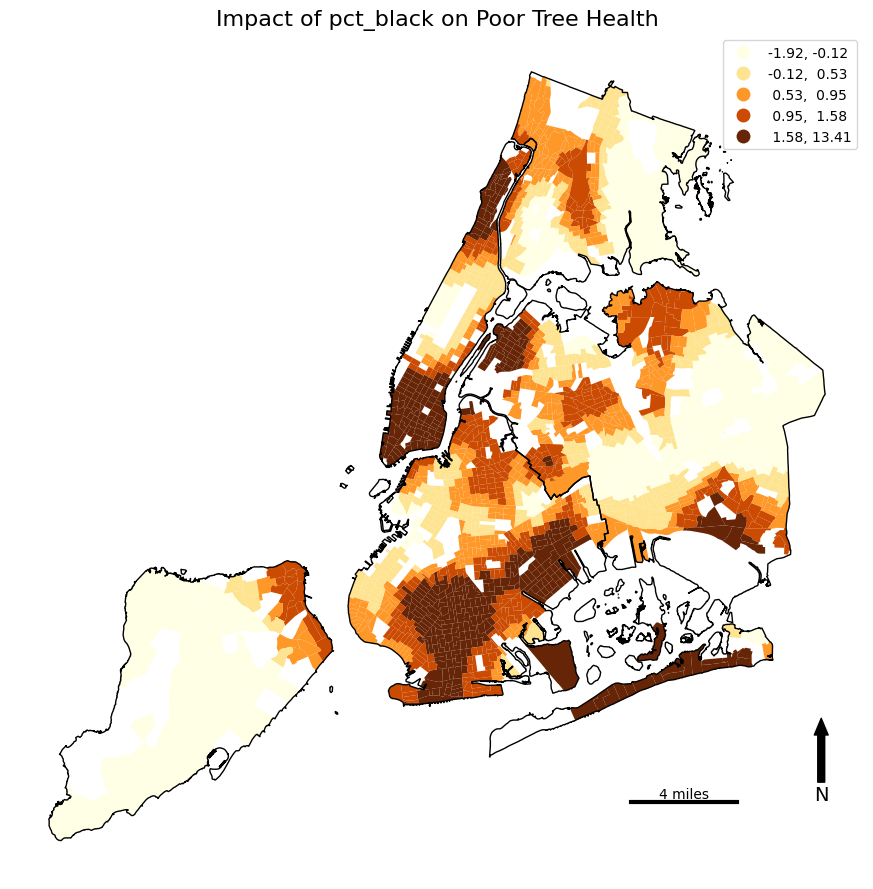

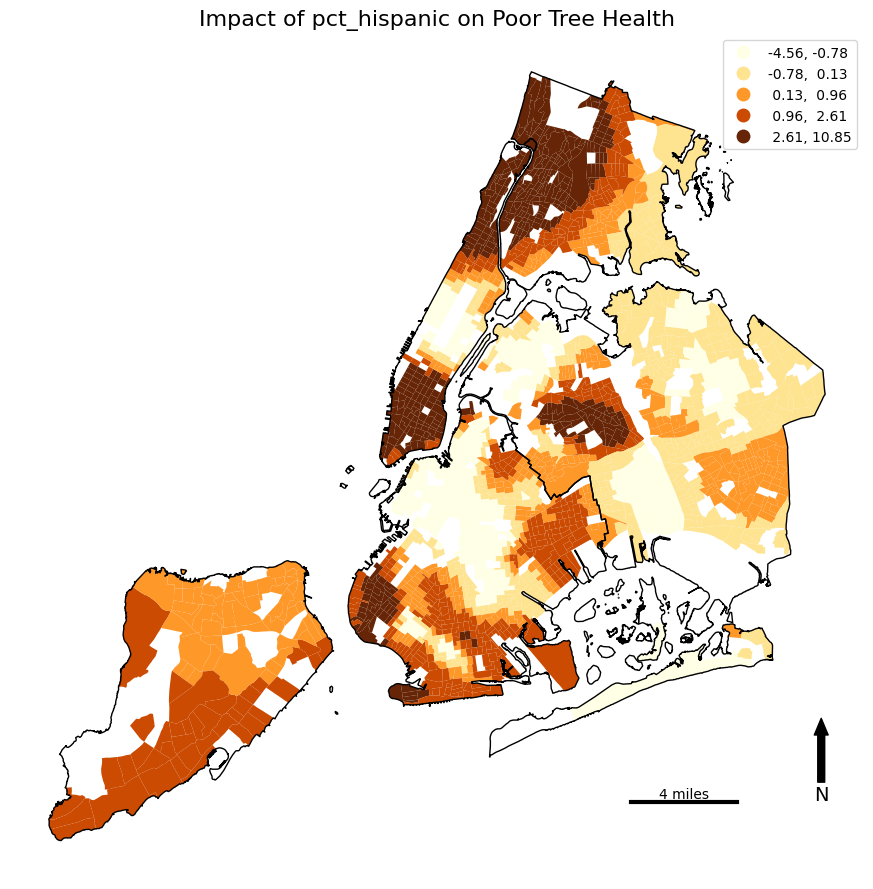

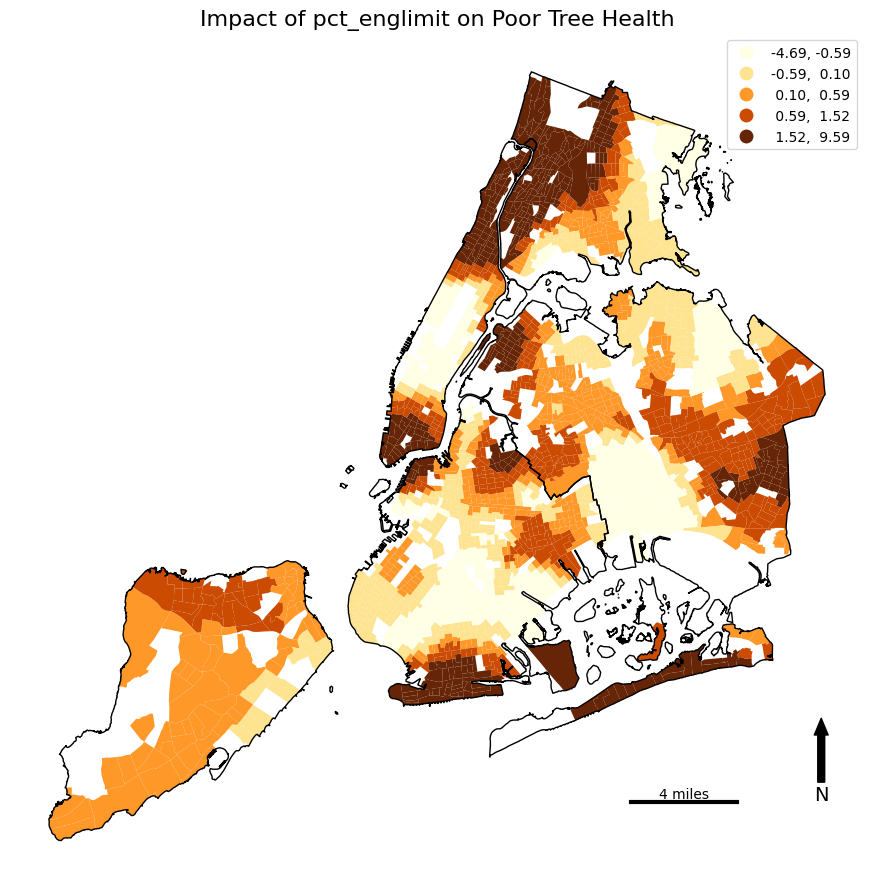

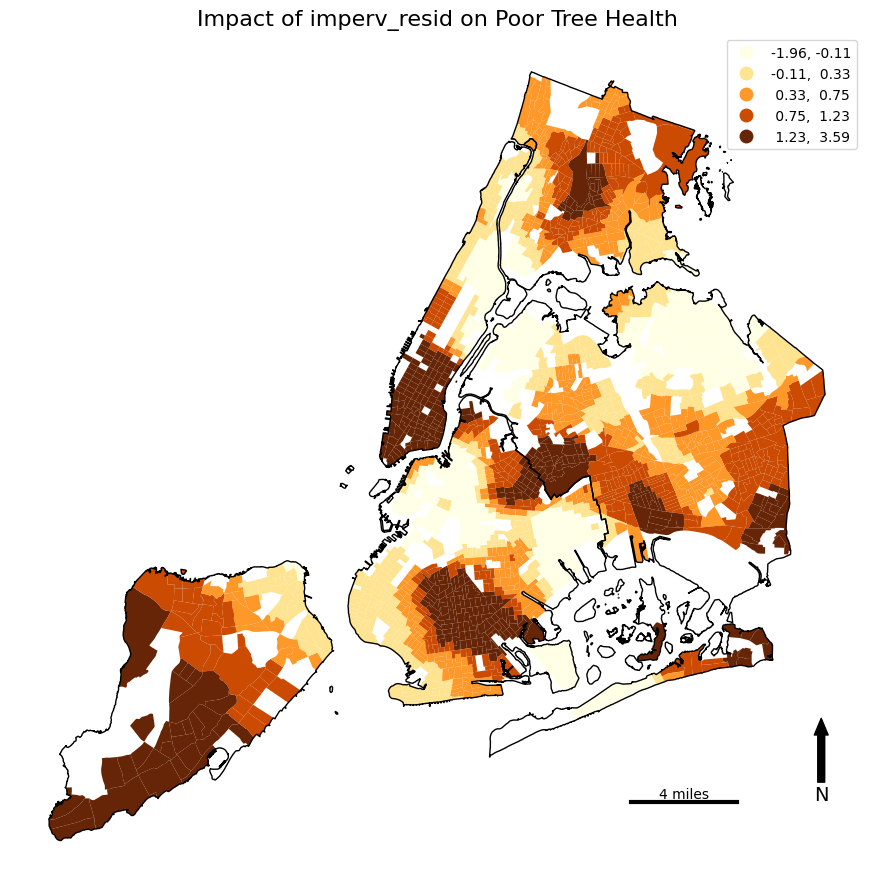

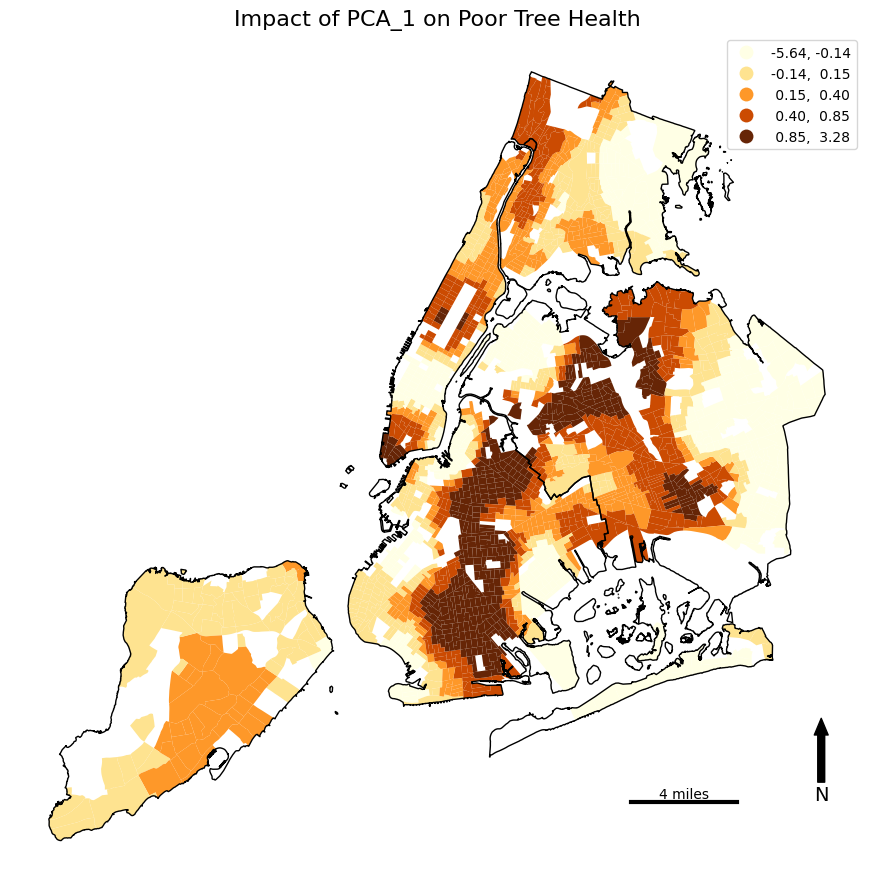

In [ ]:
coef_cols = [col for col in gwr_df_clean.columns if col.startswith("coef_")]

for col in coef_cols:
    fig, ax = plt.subplots(1, 1, figsize=(11, 9))

    gwr_df_clean.plot(
        column=col,
        cmap="YlOrBr",
        scheme="quantiles",
        k=5,
        legend=True,
        ax=ax,
        edgecolor="none"
    )

    boroughs_gdf.boundary.plot(ax=ax, color="black", linewidth=1)
    add_north_arrow(ax)
    add_scale_bar(ax, gwr_df_clean)
    ax.set_title(f"Impact of {col.replace('coef_', '')} on Poor Tree Health", fontsize=16)
    ax.axis("off")

    plt.tight_layout()
    plt.show()
